# Preprocessing pipeline

Goal: turn the raw CSV into a clean table of numbers the model can actually eat — and do it the **same way every time**, so test data never sneaks into training decisions.

Based on what the EDA showed us:
1. Drop rows where `rating` is missing (can't train on missing answers).
2. Build a few handy features from `review_text` (length, word count) and `review_date` (year, month, weekday).
3. Fill missing values differently depending on the column.
4. Turn text categories into numbers: **one-hot** when there are few values, **ordinal** when there are many.
5. Rescale numbers so they're on similar ranges (linear models care about this; trees don't, but it doesn't hurt them).
6. Wrap it all in one `ColumnTransformer` so training, testing, and any future prediction go through the exact same recipe.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import joblib

from sklearn.model_selection import train_test_split

from src.features import (
    RAW_PATH, PROCESSED_DIR, MODELS_DIR,
    NUM_COLS, LOW_CARD_COLS, HIGH_CARD_COLS,
    add_engineered_features, make_preprocessor,
)

In [2]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RAW_PATH)
print('Raw shape:', df.shape)

# If rating is missing, drop the row.
df = df.dropna(subset=['rating']).reset_index(drop=True)
print('After dropping rows with no rating:', df.shape)

Raw shape: (2514, 15)
After dropping rows with no rating: (2477, 15)


## Feature engineering

Three things we learned by actually inspecting the raw data:

- **`app_version`** has 2055 unique values across 2477 rows (examples: `"12.2.52.762"`, `"v14.8.26"`). As-is it behaves like a row identifier. The **major version** alone gives us 30 meaningful values — so we parse that out and drop the original.
- **`review_date`** — storing it as epoch seconds gives one unique value per row (another row ID). We keep only `year` / `month` / `dayofweek`.
- **`review_text`** — only 739 unique texts. The top 5 templates each repeat 175–190+ times. It's effectively a categorical feature with very strong signal, not free text. We route it into the high-cardinality group (ordinal encoding) rather than dropping it.

Everything else stays deterministic and row-level, so engineering it here (outside the transformer) is still safe.

In [ ]:
df = add_engineered_features(df)

X = df.drop(columns='rating')
y = df['rating']

print('Feature matrix shape:', X.shape)
print('\nColumns:', list(X.columns))

Feature matrix shape: (2477, 16)

Columns: ['app_name', 'app_category', 'review_text', 'review_language', 'verified_purchase', 'device_type', 'num_helpful_votes', 'user_age', 'user_country', 'user_gender', 'review_length', 'review_word_count', 'review_year', 'review_month', 'review_dayofweek', 'app_major_version']


## Column groups

| Group | Columns | How we fill missing | How we turn it into numbers |
|---|---|---|---|
| numbers | `user_age`, `num_helpful_votes`, `verified_purchase` (0/1), `review_length`, `review_word_count`, `review_year`, `review_month`, `review_dayofweek`, `app_major_version` | median | `StandardScaler` (rescale) |
| few unique values | `app_category`, `review_language`, `device_type`, `user_gender` | `"Unknown"` | `OneHotEncoder` (one column per value) |
| many unique values | `app_name`, `user_country`, `review_text` | `"Unknown"` | `OrdinalEncoder` (one integer per value) |

**Why `review_text` sits in "many unique values":** 739 unique strings, most dominated by a handful of repeating templates. Ordinal encoding gives each template its own integer code; the model (especially a tree-based one) will happily learn that certain codes map to specific rating bands. For simple linear models this is a weak encoding, but the upcoming feature-selection step will confirm whether it's worth the complexity.

**Why `app_major_version` is a number instead of a category:** versions have a natural order (v12 comes after v11), so treating them as a numeric axis preserves information that a categorical encoder would throw away.

In [ ]:
print('numeric   :', NUM_COLS)
print('low-card  :', LOW_CARD_COLS)
print('high-card :', HIGH_CARD_COLS)

assert set(NUM_COLS + LOW_CARD_COLS + HIGH_CARD_COLS) == set(X.columns), \
    f'Mismatch: {set(X.columns) ^ set(NUM_COLS + LOW_CARD_COLS + HIGH_CARD_COLS)}'

numeric   : ['num_helpful_votes', 'user_age', 'review_length', 'review_word_count', 'review_year', 'review_month', 'review_dayofweek', 'verified_purchase', 'app_major_version']
low-card  : ['app_category', 'review_language', 'device_type', 'user_gender']
high-card : ['app_name', 'user_country', 'review_text']


In [ ]:
preprocessor = make_preprocessor()
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('low_cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name`

## Train / test split

The monthly rating plot from the EDA tells us which split to use:
- **Flat line** → random 80/20 split is fine.
- **Clear trend over time** → train on older reviews, test on newer ones. Otherwise the model gets to peek at "the future" and we overestimate how good it is.

Default is random. Flip the flag if the EDA showed a time trend.

In [6]:
TEMPORAL_SPLIT = False  # set True if EDA showed monthly drift

if TEMPORAL_SPLIT:
    order = X['review_date_epoch'].argsort().values
    cutoff = int(len(order) * 0.8)
    train_idx, test_idx = order[:cutoff], order[cutoff:]
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (1981, 16) | Test: (496, 16)


In [7]:
X_train_t = preprocessor.fit_transform(X_train)
X_test_t  = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print('Transformed train shape:', X_train_t.shape)
print('Transformed test shape :', X_test_t.shape)
print('Total output features  :', len(feature_names))

Transformed train shape: (1981, 64)
Transformed test shape : (496, 64)
Total output features  : 64


## Save the results

- **`preprocessor.joblib`** — the fitted transformer. `03_modeling.ipynb` loads this so it doesn't have to redo any of the work here.
- **`train.csv` / `test.csv`** — the actual transformed numbers, ready to feed into a model.

If we change anything about preprocessing, we re-run only this notebook and everything downstream picks up the new version.

In [8]:
joblib.dump(preprocessor, MODELS_DIR / 'preprocessor.joblib')

train_df = pd.DataFrame(X_train_t, columns=feature_names)
train_df['rating'] = y_train.values
train_df.to_csv(PROCESSED_DIR / 'train.csv', index=False)

test_df = pd.DataFrame(X_test_t, columns=feature_names)
test_df['rating'] = y_test.values
test_df.to_csv(PROCESSED_DIR / 'test.csv', index=False)

print('Saved:')
print(' -', MODELS_DIR / 'preprocessor.joblib')
print(' -', PROCESSED_DIR / 'train.csv', train_df.shape)
print(' -', PROCESSED_DIR / 'test.csv',  test_df.shape)

Saved:
 - /Users/gabriel/Desktop/SIGMOID/Sigmoid-Intership/Exam/models/preprocessor.joblib
 - /Users/gabriel/Desktop/SIGMOID/Sigmoid-Intership/Exam/data/processed/train.csv (1981, 65)
 - /Users/gabriel/Desktop/SIGMOID/Sigmoid-Intership/Exam/data/processed/test.csv (496, 65)


## Feature selection — mutual information

The EDA showed η values for the raw categoricals and Pearson for the numerics, but those were two different scales and they ignored the engineered features (`review_length`, calendar features). Now that we have the full transformed matrix, we can compare **every feature on the same scale** using **mutual information (MI)**.

Why MI instead of Pearson:
- Works for both numeric and categorical features after encoding.
- Detects **non-linear** relationships (Pearson only catches linear).
- Always ≥ 0, so we can rank features directly.

Plan: compute MI against `rating`, rank features, drop the ones close to zero. The modeling notebook will then train on the filtered set and on the full set for comparison.

In [ ]:
from sklearn.feature_selection import mutual_info_regression
import matplotlib.pyplot as plt

# MI runs on the already-transformed matrix, so every feature is on the same scale
mi_scores = mutual_info_regression(X_train_t, y_train, random_state=42)

mi_df = pd.DataFrame({'feature': feature_names, 'mi_score': mi_scores})
mi_df = mi_df.sort_values('mi_score', ascending=False).reset_index(drop=True)

print('Top 10 features by mutual information with rating:')
print(mi_df.head(10).round(4).to_string(index=False))
print('\nBottom 5 features:')
print(mi_df.tail(5).round(4).to_string(index=False))
print(f'\nFeatures with MI = 0 (pure noise): {(mi_df["mi_score"] == 0).sum()}')

Top 10 features by mutual information with rating:
                            feature  mi_score
        low_cat__review_language_it    0.0364
                  num__review_month    0.0278
 low_cat__app_category_Productivity    0.0266
    low_cat__app_category_Education    0.0226
        low_cat__review_language_en    0.0204
        low_cat__review_language_ru    0.0185
low_cat__app_category_Communication    0.0153
        low_cat__review_language_ko    0.0144
       low_cat__device_type_Android    0.0134
        low_cat__review_language_hi    0.0132

Bottom 5 features:
                      feature  mi_score
       num__verified_purchase       0.0
  low_cat__review_language_ja       0.0
low_cat__app_category_Finance       0.0
  low_cat__review_language_ms       0.0
  low_cat__review_language_fi       0.0

Features with MI = 0 (pure noise): 35


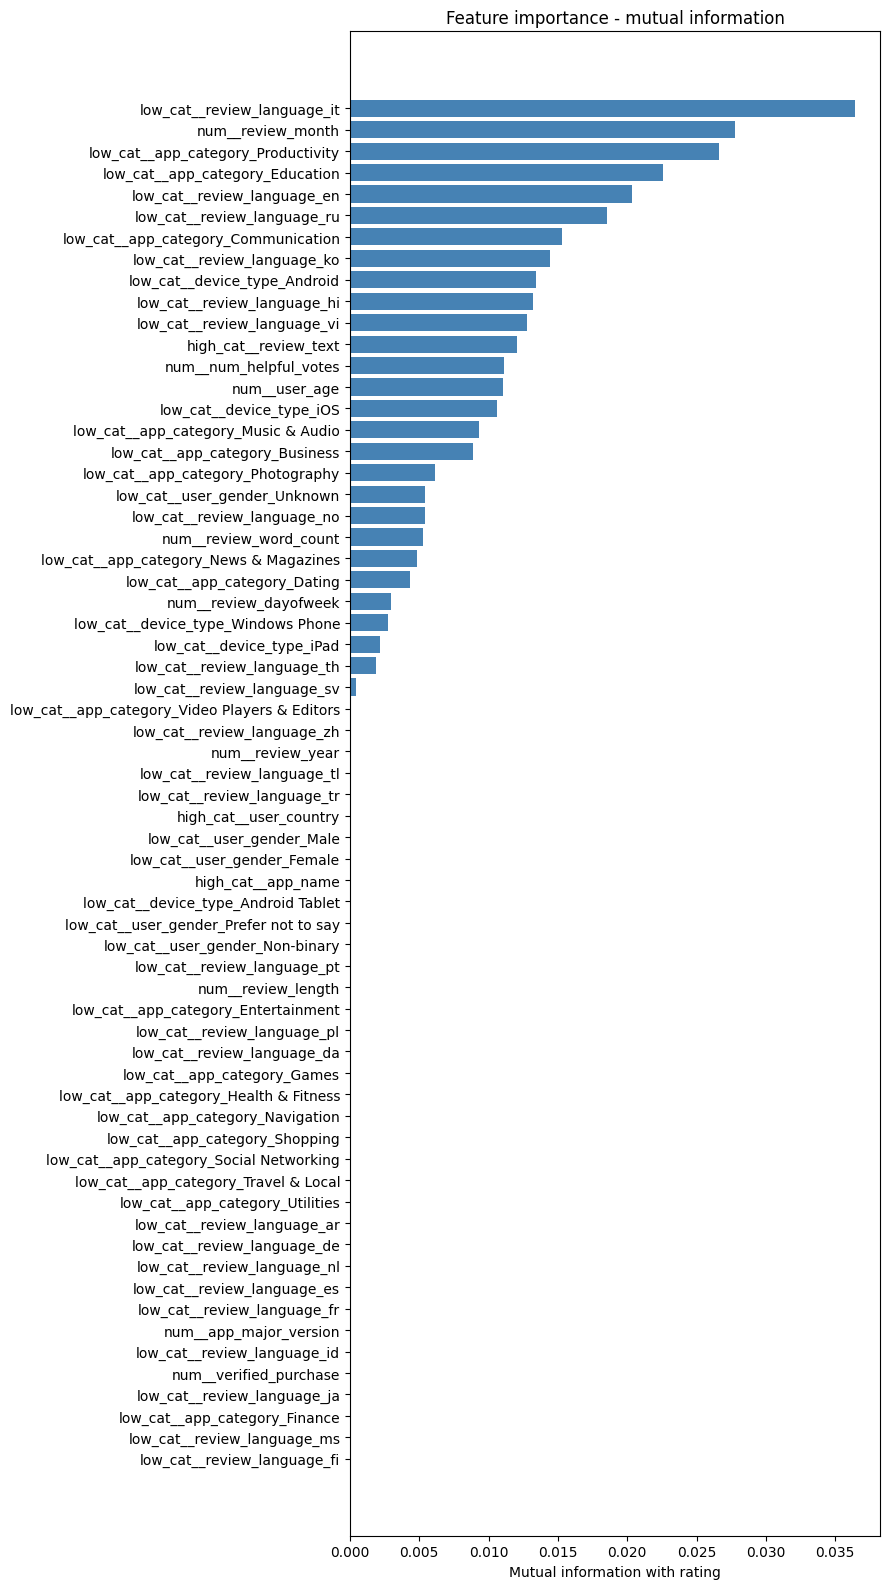

In [ ]:
plt.figure(figsize=(9, max(4, 0.25 * len(mi_df))))
plt.barh(mi_df['feature'][::-1], mi_df['mi_score'][::-1], color='steelblue')
plt.xlabel('Mutual information with rating')
plt.title('Feature importance - mutual information')
plt.tight_layout()
plt.show()

### How to read the ranking

- **MI = 0** means the feature carries no detectable relationship with `rating` — safe to drop.
- **Low but non-zero MI** (say `< 0.01`) means the signal is weak. Keeping these features costs memory and adds overfitting risk on a 2477-row dataset, while adding little.
- **High MI** confirms the feature should stay. We expect `review_text` and `app_name` at the top given what we saw in the data.

Threshold choice: `0.01` is a pragmatic default — strict enough to drop pure noise and near-noise, permissive enough to keep anything that might help a non-linear model. Not magic; just a reasonable cut point for a small dataset.

In [ ]:
MI_THRESHOLD = 0.01

selected_features = mi_df.loc[mi_df['mi_score'] > MI_THRESHOLD, 'feature'].tolist()
print(f'Kept {len(selected_features)} / {len(mi_df)} features (MI > {MI_THRESHOLD})')


mi_df.to_csv(PROCESSED_DIR / 'feature_importance.csv', index=False)

train_sel = train_df[selected_features + ['rating']]
test_sel  = test_df[selected_features + ['rating']]
train_sel.to_csv(PROCESSED_DIR / 'train_selected.csv', index=False)
test_sel.to_csv(PROCESSED_DIR / 'test_selected.csv', index=False)

print('\nSaved:')
print(' -', PROCESSED_DIR / 'feature_importance.csv', '(full ranking)')
print(' -', PROCESSED_DIR / 'train_selected.csv', train_sel.shape)
print(' -', PROCESSED_DIR / 'test_selected.csv',  test_sel.shape)

Kept 15 / 64 features (MI > 0.01)

Saved:
 - /Users/gabriel/Desktop/SIGMOID/Sigmoid-Intership/Exam/data/processed/feature_importance.csv (full ranking)
 - /Users/gabriel/Desktop/SIGMOID/Sigmoid-Intership/Exam/data/processed/train_selected.csv (1981, 16)
 - /Users/gabriel/Desktop/SIGMOID/Sigmoid-Intership/Exam/data/processed/test_selected.csv (496, 16)
